In [1]:
import re
import unicodedata
from pathlib import Path

import joblib
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)


# 폰트 설정 (Windows 기준 Malgun Gothic, 에러 방지용 기본 설정 포함)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

RANDOM_STATE = 42
DATA_DIR = Path("dataset")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

DATA_PATH_1 = DATA_DIR / "dataset1.csv"
DATA_PATH_2 = DATA_DIR / "dataset2.csv"
DATA_PATH_3 = DATA_DIR / "dataset3.csv"

print("현재 작업 폴더:", Path.cwd())
print("데이터 폴더 존재:", DATA_DIR.exists())
print("모델 저장 폴더:", MODEL_DIR.resolve())

현재 작업 폴더: c:\AIproject\ML_final
데이터 폴더 존재: True
모델 저장 폴더: C:\AIproject\ML_final\models


In [2]:
# 2. CSV 읽기 함수
def load_csv(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"파일을 찾을 수 없습니다: {path}\n"
            "프로젝트 폴더 안 dataset 폴더에 CSV 파일이 있는지 확인하세요."
        )

    last_error = None
    for encoding in ("utf-8-sig", "utf-8", "cp949"):
        try:
            # sep=None은 쉼표/탭 등 구분자를 자동 추정합니다.
            df = pd.read_csv(path, encoding=encoding, sep=None, engine="python")
            df.columns = [str(c).strip().replace("\ufeff", "") for c in df.columns]
            print(f"로드 완료: {path} | 인코딩={encoding} | 크기={df.shape}")
            print("컬럼:", df.columns.tolist())
            return df
        except (UnicodeDecodeError, pd.errors.ParserError) as e:
            last_error = e

    raise ValueError(f"CSV 파일을 읽지 못했습니다: {path}. 마지막 오류: {last_error}")


def standardize_binary_data(
    df,
    dataset_name,
    text_candidates=("content", "text"),
    label_candidates=("label",),
):
    """스팸, 피싱 모델 데이터의 텍스트/라벨 컬럼을 content/label로 통일합니다."""
    df = df.copy()
    df.columns = [str(c).strip() for c in df.columns]

    text_col = next((c for c in text_candidates if c in df.columns), None)
    label_col = next((c for c in label_candidates if c in df.columns), None)

    if text_col is None:
        raise ValueError(
            f"{dataset_name}: 텍스트 컬럼을 찾지 못했습니다. 현재 컬럼={df.columns.tolist()}"
        )
    if label_col is None:
        raise ValueError(
            f"{dataset_name}: 라벨 컬럼을 찾지 못했습니다. 현재 컬럼={df.columns.tolist()}"
        )

    data = df[[text_col, label_col]].copy()
    data.columns = ["content", "label"]
    data["content"] = data["content"].fillna("").astype(str).str.strip()
    data["label"] = pd.to_numeric(data["label"], errors="coerce")
    data = data.dropna(subset=["label"])
    data = data[data["label"].isin([0, 1])].copy()
    data["label"] = data["label"].astype(int)
    data = data[data["content"] != ""]
    data = data.drop_duplicates(subset=["content", "label"]).reset_index(drop=True)

    if data.empty:
        raise ValueError(f"{dataset_name}: 사용할 수 있는 데이터가 없습니다.")

    print(f"{dataset_name}: 정리 후 {data.shape}, 라벨 분포={data['label'].value_counts().sort_index().to_dict()}")
    return data


In [3]:
# 3. 데이터 불러오기 및 컬럼 확인
data1_raw = load_csv(DATA_PATH_1)
data2_raw = load_csv(DATA_PATH_2)
data3_raw = load_csv(DATA_PATH_3)

display(data1_raw.head(3))
display(data2_raw.head(3))
display(data3_raw.head(3))


로드 완료: dataset\dataset1.csv | 인코딩=cp949 | 크기=(200000, 2)
컬럼: ['content', 'label']
로드 완료: dataset\dataset2.csv | 인코딩=utf-8-sig | 크기=(11010, 2)
컬럼: ['text', 'label']
로드 완료: dataset\dataset3.csv | 인코딩=utf-8-sig | 크기=(19009, 3)
컬럼: ['index', 'content', 'class']


,content,label
0,"""예수쟁이들은 모하냐?저 주둥이를 안 틀어막고?같은 것들이냐?""",1
1,저 #@이름# 때문에 이''꼴'''났디 빨리 ''처'''내려와라 ''신물'''난다,1
2,''쪽팔려'''서 외국에서 얼굴을 못들겠다. ''Fuxx''' MBC너넨 영원히 '...,1


,text,label
0,ユ냥 셍활비가 식비야 ㅋㅋ,0
1,근닉까 그 롱롱 섣절리 한 병원은 묵묵부답이래.,0
2,多른 거 ㅋㅋ 죻야햐쟎야?,0


,index,content,class
0,2.0,"엄마 나 폰이 망가져서 수리맡기고 컴퓨터 스팸, 피싱나라로 메시지 보내고 있어 엄마 지금 바뻐?",2
1,2.0,[국외발신]\r\n[코인원]\r\n고객님계정이\r\n해외IP에서\r\n로그인되였습니...,2
2,2.0,엄마 입금받을수있는\r\n은행계좌번호\r\n하나랑 계좌등록\r\n본인인증땜에\r\n...,2


In [4]:
# 4-1. 스팸, 피싱 모델용 dataset1과 dataset2 정리
data1 = standardize_binary_data(
    data1_raw,
    "dataset1",
    text_candidates=("content", "text"),
    label_candidates=("label",),
)

data2 = standardize_binary_data(
    data2_raw,
    "dataset2",
    text_candidates=("text", "content"),
    label_candidates=("label",),
)

print("dataset1:", data1.shape)
print("dataset2:", data2.shape)


dataset1: 정리 후 (200000, 2), 라벨 분포={0: 100000, 1: 100000}
dataset2: 정리 후 (11010, 2), 라벨 분포={0: 5505, 1: 5505}
dataset1: (200000, 2)
dataset2: (11010, 2)


In [5]:
# 4-2. 비속어, 유해 표현 모델용 dataset3 정리
required_columns = {"content", "class"}
if not required_columns.issubset(data3_raw.columns):
    raise ValueError(
        "dataset3.csv에는 'content'와 'class' 컬럼이 필요합니다. "
        f"현재 컬럼={data3_raw.columns.tolist()}"
    )

word_data = data3_raw[["content", "class"]].copy()
word_data["content"] = word_data["content"].fillna("").astype(str).str.strip()
word_data["class"] = pd.to_numeric(word_data["class"], errors="coerce")
word_data = word_data.dropna(subset=["class", "content"])
word_data = word_data[word_data["class"].isin([1, 2])].copy()
word_data = word_data[word_data["content"] != ""]

# class 1 -> label 0 (정상), class 2 -> label 1 (광고/스팸)
# class 3은 위 필터에서 제외됩니다.
word_data["label"] = (word_data["class"] == 2).astype(int)
word_data = word_data[["content", "label"]]
word_data = word_data.drop_duplicates(subset=["content", "label"]).reset_index(drop=True)

print("dataset3 변환 후 데이터:", word_data.shape)
print("라벨 분포:", word_data["label"].value_counts().sort_index().to_dict())
display(word_data.head(10))

if word_data["label"].nunique() < 2:
    raise ValueError("dataset3에는 class 1과 class 2가 모두 있어야 합니다.")


dataset3 변환 후 데이터: (13447, 2)
라벨 분포: {0: 5776, 1: 7671}


,content,label
0,"엄마 나 폰이 망가져서 수리맡기고 컴퓨터 스팸, 피싱나라로 메시지 보내고 있어 엄마 지금 바뻐?",1
1,[국외발신]\r\n[코인원]\r\n고객님계정이\r\n해외IP에서\r\n로그인되였습니...,1
2,엄마 입금받을수있는\r\n은행계좌번호\r\n하나랑 계좌등록\r\n본인인증땜에\r\n...,1
3,엄마 바빠?나지금\r\n핸드폰 고장나서 매장에 수리맡기고\r\n급한대로 예전에\r\...,1
4,엄마~ 바빠?\r\n엄마 나 급한 일이 좀 생겨서…\r\n지금 98만원만 입금해 줄...,1
5,"엄마 나 폰고장나서 수리 맡기고 스팸, 피싱나\r\n가입한거로 스팸, 피싱하고 있어 피씨용이라\r...",1
6,"엄마 나 핸드폰 고장나서\r\n서비스 맡기고 스팸, 피싱나라\r\n접해서 스팸, 피싱하는거야\r\...",1
7,[web 발신]\r\n아빠 나지금폰\r\n액정나가서\r\n않되\r\n01059680...,1
8,엄마 나 핸드폰 고장나서\r\n수리맡기고 컴터로\r\n새카톡만들엇어~ 010\r\n...,1
9,엄마 바빠? 나 지금\r\n핸드폰 고장나서\r\n매장에 수리맡기고\r\n급한대로 예...,1


In [24]:
# word_data 전처리 완료 후
# train_test_split() 실행 전

normal_greetings = [
    "안녕하세요. 신규 가입 시 현금 혜택을 드립니다.",
    "안녕하세요. 지금 가입하면 특별 보너스를 지급합니다.",
    "안녕하세요. 한정 이벤트에 참여하고 혜택을 받아 가세요.",
    "안녕하세요. 오늘만 적용되는 특별 할인 행사입니다.",
    "안녕하세요. 무료 체험 신청 후 유료 서비스를 이용해 보세요.",
    "안녕하세요. 회원 가입만 하면 포인트를 지급합니다.",
    "안녕하세요. 추천인 코드를 입력하면 추가 보상을 드립니다.",
    "안녕하세요. 친구를 초대하고 추가 혜택을 받으세요.",
    "안녕하세요. 지금 신청하면 가입비가 면제됩니다.",
    "안녕하세요. 특별 회원으로 등록하고 혜택을 누리세요.",
    "안녕하세요. 투자 상품 가입 시 높은 수익을 보장합니다.",
    "안녕하세요. 원금 보장과 고수익을 약속하는 투자 기회입니다.",
    "안녕하세요. 소액 투자로 큰돈을 벌 수 있습니다.",
    "안녕하세요. 단기간에 수익을 올릴 수 있는 비공개 정보입니다.",
    "안녕하세요. 투자금을 입금하면 수익금을 지급해 드립니다.",
    "안녕하세요. 당첨된 상금을 받으려면 수수료를 먼저 입금하세요.",
    "안녕하세요. 경품 수령을 위해 결제 정보를 입력하세요.",
    "안녕하세요. 상품을 받으려면 인증 비용을 송금해야 합니다.",
    "안녕하세요. 계정 확인을 위해 비밀번호를 입력해 주세요.",
    "안녕하세요. 본인 확인을 위해 카드 정보를 등록하세요.",
    "안녕하세요. 계정이 정지될 예정이니 안내된 링크에서 확인하세요.",
    "안녕하세요. 결제 오류가 발생했습니다. 링크에서 정보를 갱신하세요.",
    "안녕하세요. 배송 주소에 문제가 있습니다. 아래 링크에서 수정하세요.",
    "안녕하세요. 택배 수령을 위해 개인정보를 입력해 주세요.",
    "안녕하세요. 미납 요금 확인을 위해 결제 정보를 등록하세요.",
    "안녕하세요. 본인 인증이 완료되지 않았습니다. 즉시 인증하세요.",
    "안녕하세요. 보안 점검을 위해 계정 정보를 다시 입력해 주세요.",
    "안녕하세요. 당첨 안내를 받으셨습니다. 지금 바로 신청하세요.",
    "안녕하세요. 신청 마감이 임박했습니다. 지금 결제해 주세요.",
    "안녕하세요. 특별한 조건으로 대출을 승인해 드립니다.",
    "안녕하세요. 신용 등급과 관계없이 대출이 가능합니다.",
    "안녕하세요. 대출 진행을 위해 선입금을 부탁드립니다.",
    "안녕하세요. 수수료를 먼저 보내면 대출금을 지급합니다.",
    "안녕하세요. 검증되지 않은 투자방에 참여하고 수익을 나누세요.",
    "안녕하세요. 비밀 투자 정보를 제공하니 바로 송금하세요.",
    "안녕하세요. 지금 구매하면 추가 상품을 무료로 제공합니다.",
    "안녕하세요. 모든 상품을 파격적인 가격으로 판매합니다.",
    "안녕하세요. 구매 링크를 통해 주문하고 할인 혜택을 받으세요.",
    "안녕하세요. 매일 광고 메시지를 보내드리니 가입해 주세요.",
    "안녕하세요. 원하지 않는 광고 수신에 동의하고 혜택을 받으세요.",
    "안녕하세요. 연락처를 등록하면 홍보 자료를 보내드립니다.",
    "안녕하세요. 단체 채팅방에 참여하면 특별 정보를 제공합니다.",
    "안녕하세요. 자동 수익 프로그램에 가입하고 입금하세요.",
    "안녕하세요. 당첨금을 받으려면 계좌 정보를 보내 주세요.",
    "안녕하세요. 환급금을 지급하기 위해 개인정보가 필요합니다.",
    "안녕하세요. 확인되지 않은 사이트에서 인증 절차를 진행하세요.",
    "안녕하세요. 지금 접속하지 않으면 혜택이 사라집니다.",
    "안녕하세요. 이 기회를 놓치지 말고 즉시 신청하세요.",
    "안녕하세요. 가입 후 결제하면 추가 포인트를 지급합니다.",
    "안녕하세요. 광고를 확인하고 보상을 받으려면 등록하세요.",
]

normal_greeting_df = pd.DataFrame({
    "content": normal_greetings,
    "label": [0] * len(normal_greetings),
})

word_data = pd.concat(
    [word_data, normal_greeting_df],
    ignore_index=True
)

# 이후 기존 train_test_split() 실행

In [25]:
# 5. dataset1을 80:20으로 학습/테스트 분리
X1 = data1["content"]
y1 = data1["label"]

X_train_base, X_test, y_train_base, y_test = train_test_split(
    X1,
    y1,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y1,
)

print("dataset1 학습 데이터:", len(X_train_base))
print("dataset1 테스트 데이터:", len(X_test))
print("학습 라벨 분포:", y_train_base.value_counts().sort_index().to_dict())
print("테스트 라벨 분포:", y_test.value_counts().sort_index().to_dict())


dataset1 학습 데이터: 160000
dataset1 테스트 데이터: 40000
학습 라벨 분포: {0: 80000, 1: 80000}
테스트 라벨 분포: {0: 20000, 1: 20000}


In [26]:
# 6. 스팸, 피싱 모델 학습 데이터 결합: dataset1 학습 부분 + dataset2
char_train = pd.concat(
    [
        pd.DataFrame({"content": X_train_base, "label": y_train_base}),
        data2[["content", "label"]],
    ],
    ignore_index=True,
)

char_train["content"] = char_train["content"].fillna("").astype(str).str.strip()
char_train["label"] = pd.to_numeric(char_train["label"], errors="coerce")
char_train = char_train.dropna(subset=["label"])
char_train = char_train[char_train["label"].isin([0, 1])].copy()
char_train["label"] = char_train["label"].astype(int)
char_train = char_train[char_train["content"] != ""]

# 동일 스팸, 피싱에 상충하는 라벨이 있으면 학습에서 제외
label_counts = char_train.groupby("content")["label"].nunique()
conflicting_texts = set(label_counts[label_counts > 1].index)
if conflicting_texts:
    print("상충 라벨로 제외할 스팸, 피싱 수:", len(conflicting_texts))
    char_train = char_train[~char_train["content"].isin(conflicting_texts)].copy()

char_train = char_train.drop_duplicates(subset=["content", "label"]).reset_index(drop=True)

print("스팸, 피싱 모델 학습 데이터:", char_train.shape)
print("스팸, 피싱 모델 라벨 분포:", char_train["label"].value_counts().sort_index().to_dict())

if char_train["label"].nunique() < 2:
    raise ValueError("스팸, 피싱 모델 학습 데이터에는 라벨 0과 1이 모두 필요합니다.")


스팸, 피싱 모델 학습 데이터: (171010, 2)
스팸, 피싱 모델 라벨 분포: {0: 85505, 1: 85505}


In [27]:
# 7-1. 유해,비속어 모델용 정규화
def normalize_char(text):
    text = unicodedata.normalize("NFKC", str(text)).lower()

    # 1. 공백을 제거한 원본 스팸, 피싱열
    original = re.sub(r"\s+", "", text)

    # 2. 한글 사이에 있는 숫자·특수스팸, 피싱 제거
    normalized = re.sub(
        r"(?<=[가-힣])[0-9\W_]+(?=[가-힣])",
        "",
        original
    )

    # 3. 원본과 정규화 스팸, 피싱열을 함께 반환
    return original + " " + normalized


# 7-2. 스팸, 광고 모델용 정규화
def normalize_word(text):
    text = unicodedata.normalize("NFKC", str(text))
    text = text.lower()
    # 한글/영문/숫자/공백은 유지하고 그 외 기호는 공백으로 변경
    text = re.sub(r"[^\w\s가-힣]", " ", text)
    text = text.replace("_", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text


X_test_char = X_test.map(normalize_char)
X_test_word = X_test.map(normalize_word)
y_test_clean = y_test.astype(int).reset_index(drop=True)

print("스팸, 피싱 정규화 예시:", X_test_char.iloc[0])
print("비속어, 유해 정규화 예시:", X_test_word.iloc[0])


스팸, 피싱 정규화 예시: #@이름#은''대깨문'''들과''문빠'''들데리고당신고향으로가라!#@이름#일가의고향북한흥남으로가라!왜?일가모두북한출신인#@이름#이대한민국대통령을하는가?당신고향으로''끄지'''세요! #@이름은대깨문들과문빠들데리고당신고향으로가라이름일가의고향북한흥남으로가라왜일가모두북한출신인이름이대한민국대통령을하는가당신고향으로끄지세요!
비속어, 유해 정규화 예시: 이름 은 대깨문 들과 문빠 들 데리고 당신 고향으로 가라 이름 일가의 고향 북한 흥남으로가라 왜 일가모두 북한 출신인 이름 이 대한민국 대통령을 하는가 당신 고향으로 끄지 세요


In [28]:
# 8. 공통 학습/평가 함수 (SVM 적용 버전)
def train_evaluate_model(
    train_data,
    test_text,
    test_labels,
    normalizer,
    analyzer,
    ngram_range,
    model_name,
    vectorizer_filename,
    model_filename,
    max_features=100_000,
    threshold=0.5,
    min_df=2,
):
    train_data = train_data[["content", "label"]].copy()
    train_data["content"] = train_data["content"].map(normalizer)
    train_data["label"] = train_data["label"].astype(int)
    train_data = train_data[train_data["content"] != ""]

    # 정규화 후 상충 라벨 제거 및 중복 제거
    label_counts = train_data.groupby("content")["label"].nunique()
    conflicts = set(label_counts[label_counts > 1].index)
    if conflicts:
        train_data = train_data[~train_data["content"].isin(conflicts)].copy()
    train_data = train_data.drop_duplicates(subset=["content", "label"]).reset_index(drop=True)

    if train_data["label"].nunique() < 2:
        raise ValueError(f"{model_name}: 학습 데이터에 라벨 0과 1이 모두 필요합니다.")

    X_train_model = train_data["content"]
    y_train_model = train_data["label"]
    X_test_model = test_text.map(normalizer)

    # 학습 데이터에서만 fit하여 테스트 데이터 누수를 방지
    vectorizer = TfidfVectorizer(
        analyzer=analyzer,
        ngram_range=ngram_range,
        min_df=min_df,
        max_features=max_features,
        sublinear_tf=True,
    )
    X_train_vec = vectorizer.fit_transform(X_train_model)
    print("학습 데이터 수:", len(X_train_model))
    print("TF-IDF 벡터 크기:", X_train_vec.shape)
    print("SVM 학습 시작")
    X_test_vec = vectorizer.transform(X_test_model)

    base_model = LinearSVC(
        C=1.0,
        class_weight="balanced",
        max_iter=2000,
        random_state=RANDOM_STATE,
    )

    model = CalibratedClassifierCV(
        estimator=base_model,
        method="sigmoid",
        cv=3,
    )

    model.fit(X_train_vec, y_train_model)

    # 유해·스팸일 확률
    y_proba = model.predict_proba(X_test_vec)[:, 1]

    # 기본 임계값 0.5로 분류
    y_pred = (y_proba >= 0.5).astype(int)

    print("\n" + "=" * 65)
    print(model_name)
    print("=" * 65)
    print("학습 데이터 수:", len(train_data))
    print("특징 개수:", len(vectorizer.vocabulary_))
    print(f"Accuracy (threshold={threshold:.2f}): {accuracy_score(test_labels, y_pred):.4f}")
    print("\n분류 리포트:")
    print(classification_report(
        test_labels,
        y_pred,
        labels=[0, 1],
        target_names=["정상(0)", "유해·스팸(1)"],
        zero_division=0,
    ))

    cm = confusion_matrix(test_labels, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["정상(0)", "유해·스팸(1)"],
    )
    disp.plot(values_format="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.tight_layout()
    plt.show()

    # 여러 임계값 비교
    rows = []
    for th in [0.3, 0.4, 0.5, 0.6, 0.7]:
        pred = (y_proba >= th).astype(int)
        precision, recall, f1, _ = precision_recall_fscore_support(
            test_labels,
            pred,
            labels=[1],
            average=None,
            zero_division=0,
        )
        rows.append({
            "threshold": th,
            "accuracy": accuracy_score(test_labels, pred),
            "spam_toxic_precision": precision[0],
            "spam_toxic_recall": recall[0],
            "spam_toxic_f1": f1[0],
        })

    threshold_results = pd.DataFrame(rows)
    display(threshold_results)

    # 모델과 벡터라이저 저장
    vectorizer_path = MODEL_DIR / vectorizer_filename
    model_path = MODEL_DIR / model_filename
    joblib.dump(vectorizer, vectorizer_path)
    joblib.dump(model, model_path)

    print("벡터라이저 저장:", vectorizer_path.resolve())
    print("모델 저장:", model_path.resolve())

    return {
        "vectorizer": vectorizer,
        "model": model,
        "probabilities": y_proba,
        "predictions": y_pred,
        "threshold_results": threshold_results,
    }

학습 데이터 수: 170995
TF-IDF 벡터 크기: (170995, 30000)
SVM 학습 시작

char_svm_model
학습 데이터 수: 170995
특징 개수: 30000
Accuracy (threshold=0.50): 0.9871

분류 리포트:
              precision    recall  f1-score   support

       정상(0)       0.98      0.99      0.99     20000
    유해·스팸(1)       0.99      0.98      0.99     20000

    accuracy                           0.99     40000
   macro avg       0.99      0.99      0.99     40000
weighted avg       0.99      0.99      0.99     40000



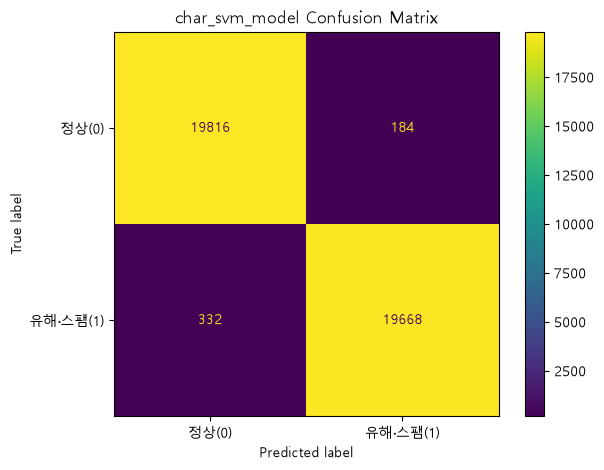

,threshold,accuracy,spam_toxic_precision,spam_toxic_recall,spam_toxic_f1
0,0.3,0.984975,0.978397,0.99185,0.985078
1,0.4,0.986400,0.985671,0.98715,0.986410
2,0.5,0.987100,0.990731,0.98340,0.987052
3,0.6,0.986000,0.994254,0.97765,0.985882
4,0.7,0.983275,0.996507,0.96995,0.983049


벡터라이저 저장: C:\AIproject\ML_final\models\char_vectorizer.pkl
모델 저장: C:\AIproject\ML_final\models\char_model.pkl


In [29]:
# 9. 스팸, 피싱 TF-IDF 모델 학습
char_results = train_evaluate_model(
    train_data=char_train,
    test_text=X_test,
    test_labels=y_test_clean,
    normalizer=normalize_char,
    analyzer="char",
    ngram_range=(2, 5),
    model_name="char_svm_model", # 이름만 보기 편하게 수정 가능
    vectorizer_filename="char_vectorizer.pkl",
    model_filename="char_model.pkl",
    max_features=30_000,
    min_df=2,
)

char_vectorizer = char_results["vectorizer"]
char_model = char_results["model"]

비속어, 유해 모델 학습 데이터: 10800
비속어, 유해 모델 테스트 데이터: 2701
학습 데이터 수: 10586
TF-IDF 벡터 크기: (10586, 18331)
SVM 학습 시작

word_svm_model
학습 데이터 수: 10586
특징 개수: 18331
Accuracy (threshold=0.50): 0.9830

분류 리포트:
              precision    recall  f1-score   support

       정상(0)       0.97      0.99      0.98      1166
    유해·스팸(1)       0.99      0.98      0.98      1535

    accuracy                           0.98      2701
   macro avg       0.98      0.98      0.98      2701
weighted avg       0.98      0.98      0.98      2701



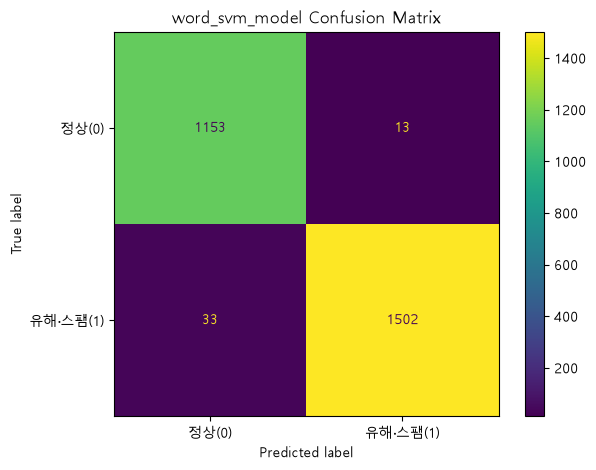

,threshold,accuracy,spam_toxic_precision,spam_toxic_recall,spam_toxic_f1
0,0.3,0.982969,0.986920,0.983062,0.984987
1,0.4,0.982599,0.989474,0.979805,0.984615
2,0.5,0.982969,0.991419,0.978502,0.984918
3,0.6,0.984080,0.994040,0.977850,0.985878
4,0.7,0.983710,0.994691,0.976547,0.985536


벡터라이저 저장: C:\AIproject\ML_final\models\word_vectorizer.pkl
모델 저장: C:\AIproject\ML_final\models\word_model.pkl


In [30]:
# 10. 비속어, 유해 TF-IDF 모델 학습 및 평가
from sklearn.model_selection import train_test_split

word_train, word_test = train_test_split(
    word_data,
    test_size=0.2,
    random_state=42,
    stratify=word_data["label"]
)

print("비속어, 유해 모델 학습 데이터:", len(word_train))
print("비속어, 유해 모델 테스트 데이터:", len(word_test))

word_results = train_evaluate_model(
    train_data=word_train,
    test_text=word_test["content"],
    test_labels=word_test["label"],
    normalizer=normalize_word,
    analyzer="word",
    ngram_range=(1, 2),
    model_name="word_svm_model", # 이름만 보기 편하게 수정 가능
    vectorizer_filename="word_vectorizer.pkl",
    model_filename="word_model.pkl",
    max_features=30_000,
    min_df=2,
)

word_vectorizer = word_results["vectorizer"]
word_model = word_results["model"]